# 1. Simple Graph

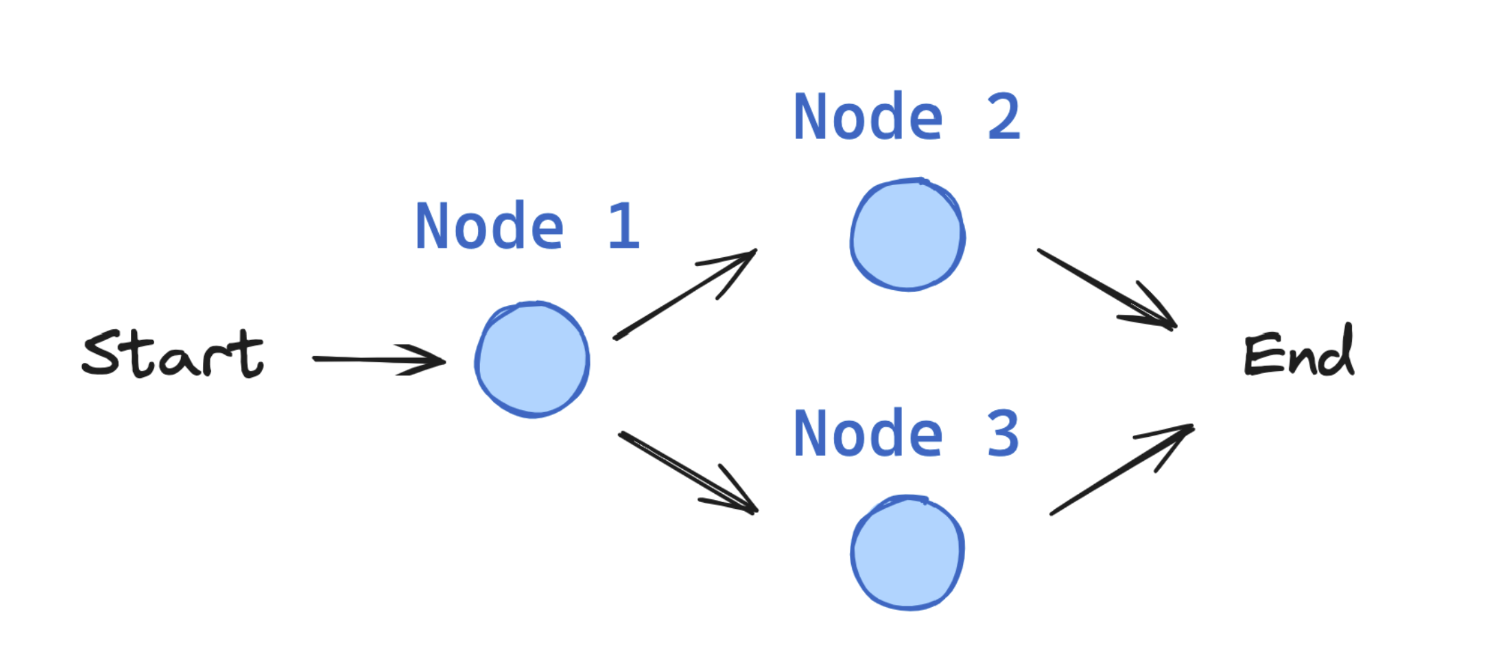

## State
In LangGraph, the State is a shared data structure that represents the **current snapshot of your application**

In [1]:
from typing_extensions import TypedDict

class State(TypedDict):
  graph_state: str

## Nodes
Nodes are just python functions.

In [7]:
def router(state):
  print("Router")
  return {"graph_state": state['graph_state'] + "I am"}

def positive(state):
  print("Positive")
  return {"graph_state": state['graph_state'] + " Happy!"}

def negative(state):
  print("Negative")
  return {"graph_state": state['graph_state'] + " sad!"}


## Edges
Edges connect the nodes.

In [8]:
import random
from typing import Literal

def decide_mood(state) -> Literal["positive", "negative"]:

  user_input = state['graph_state']

  if random.random() < 0.5:
    return "positive"

  return "negative"

## Graph
Building graph using nodes and edges with state

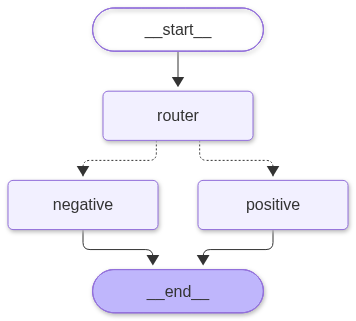

In [9]:
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END

graph = StateGraph(State)

graph.add_node("router", router)
graph.add_node("positive", positive)
graph.add_node("negative", negative)

graph.add_edge(START, "router")
graph.add_conditional_edges("router", decide_mood)
graph.add_edge("positive", END)
graph.add_edge("negative", END)

app = graph.compile()

display(Image(app.get_graph().draw_mermaid_png()))

## Graph Invokation

In [17]:
app.invoke({"graph_state" : "Hi, I am Sakshi "})

Router
Positive


{'graph_state': 'Hi, I am Sakshi I am Happy!'}